# Imports

In [ ]:
# %pip install opencv-python numpy pandas matplotlib scipy scikit-image tifffile Pillow

In [1]:
from pathlib import Path
import cv2
import json
import pandas as pd
import matplotlib.pyplot as plt
from skimage.restoration import inpaint
import hashlib
import subprocess
import numpy as np
import tifffile
from PIL import Image

from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path as MplPath
from skimage.draw import polygon2mask
import matplotlib.patches as patches
import scipy.ndimage as ndi  # Added for distance_transform_edt
from scipy.ndimage import gaussian_filter, median_filter

from skimage.filters import threshold_otsu, meijering
from skimage.measure import profile_line, label, regionprops
from skimage.morphology import remove_small_objects, remove_small_holes, disk, white_tophat
from skimage.morphology import skeletonize, binary_dilation, binary_closing, black_tophat
from skimage.morphology import closing, dilation
from scipy import interpolate, sparse
from scipy.sparse.linalg import cg, spsolve

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Data Formation

## Helpers

In [3]:
def sha256_file(path, chunk_size=1024 * 1024):
    """Compute SHA256 hash of a file so the original DNG can be tracked."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def safe_json(obj):
    """Convert non-JSON-friendly objects to strings/lists."""
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, bytes):
        try:
            return obj.decode("utf-8", errors="replace")
        except Exception:
            return str(obj)
    if isinstance(obj, (list, tuple)):
        return [safe_json(x) for x in obj]
    if isinstance(obj, dict):
        return {str(k): safe_json(v) for k, v in obj.items()}
    return obj


def extract_exiftool_metadata(dng_path):
    """
    Extract metadata using exiftool if installed.
    This is the most reliable way to get DNG/EXIF tags.
    """
    try:
        result = subprocess.run(
            ["exiftool", "-json", str(dng_path)],
            capture_output=True,
            text=True,
            check=True
        )
        data = json.loads(result.stdout)
        return data[0] if data else {}
    except FileNotFoundError:
        print("Warning: exiftool not found. Install it for better metadata extraction.")
        return {}
    except Exception as e:
        print(f"Warning: exiftool failed: {e}")
        return {}


def extract_tiff_tags(dng_path):
    """
    Extract TIFF/DNG tags using tifffile.
    This is useful even if exiftool is unavailable.
    """
    tag_data = {}

    with tifffile.TiffFile(dng_path) as tif:
        tag_data["num_pages"] = len(tif.pages)

        pages = []
        for i, page in enumerate(tif.pages):
            page_info = {
                "page_index": i,
                "shape": page.shape,
                "dtype": str(page.dtype),
                "photometric": str(page.photometric),
                "compression": str(page.compression),
                "tags": {}
            }

            for tag in page.tags.values():
                try:
                    page_info["tags"][tag.name] = safe_json(tag.value)
                except Exception:
                    page_info["tags"][tag.name] = str(tag.value)

            pages.append(page_info)

        tag_data["pages"] = pages

    return safe_json(tag_data)


def choose_best_image_page(dng_path):
    """
    Choose the largest image page from the DNG.
    This avoids accidentally using a small preview/thumbnail page.
    """
    with tifffile.TiffFile(dng_path) as tif:
        best_idx = None
        best_pixels = -1

        for i, page in enumerate(tif.pages):
            shape = page.shape

            if len(shape) < 2:
                continue

            h, w = shape[0], shape[1]
            pixels = h * w

            if pixels > best_pixels:
                best_pixels = pixels
                best_idx = i

        if best_idx is None:
            raise ValueError("No valid image page found in DNG.")

        image = tif.pages[best_idx].asarray()
        page_tags = {tag.name: safe_json(tag.value) for tag in tif.pages[best_idx].tags.values()}

    return image, best_idx, page_tags


def get_tag_value(page_tags, names, default=None):
    """Try multiple possible tag names."""
    for name in names:
        if name in page_tags:
            return page_tags[name]
    return default


def parse_black_level(black_level):
    if black_level is None:
        return None

    arr = np.array(black_level, dtype=np.float32).ravel()
    if arr.size == 0:
        return None

    return float(np.median(arr))


def parse_white_level(white_level):
    if white_level is None:
        return None

    arr = np.array(white_level, dtype=np.float32).ravel()
    if arr.size == 0:
        return None

    return float(np.max(arr))


def normalize_raw_image(image, page_tags):
    """
    Convert raw image to float32 [0, 1] when possible.
    Uses DNG BlackLevel and WhiteLevel if present.
    """
    image_f = image.astype(np.float32)

    black_level = get_tag_value(page_tags, ["BlackLevel"], default=None)
    white_level = get_tag_value(page_tags, ["WhiteLevel"], default=None)

    black = parse_black_level(black_level)

    if white_level is not None:
        white = parse_white_level(white_level)
    else:
        # Fallback based on dtype
        if np.issubdtype(image.dtype, np.integer):
            white = float(np.iinfo(image.dtype).max)
        else:
            white = float(np.nanmax(image_f))

    if black is None:
        black = 0.0

    denom = max(white - black, 1e-6)
    linear = (image_f - black) / denom
    linear = np.clip(linear, 0, 1)

    norm_info = {
        "black_level_used": black,
        "white_level_used": white,
        "normalization": "(raw - black_level) / (white_level - black_level)"
    }

    return linear.astype(np.float32), norm_info


def make_preview_png(linear_image, out_png):
    """
    Make an 8-bit display preview only.
    This should NOT be used for quantitative Hb analysis.
    """
    img = linear_image.copy()

    # Robust display scaling using percentiles
    lo, hi = np.percentile(img, [1, 99.5])
    img = (img - lo) / max(hi - lo, 1e-6)
    img = np.clip(img, 0, 1)

    if img.ndim == 2:
        img8 = (img * 255).astype(np.uint8)
        Image.fromarray(img8).save(out_png)
    elif img.ndim == 3:
        if img.shape[2] > 3:
            img = img[:, :, :3]
        img8 = (img * 255).astype(np.uint8)
        Image.fromarray(img8).save(out_png)
    else:
        raise ValueError(f"Unsupported image shape for preview: {img.shape}")


def save_linear_tiff(linear_image, out_tiff):
    """
    Save analysis image as 16-bit TIFF.
    This preserves much more useful intensity information than 8-bit PNG.
    """
    img16 = np.clip(linear_image * 65535, 0, 65535).astype(np.uint16)
    tifffile.imwrite(out_tiff, img16)


def extract_channels(linear_image):
    """
    Basic channel handling.

    Case 1:
        H x W x 3 or H x W x 4 image:
        assume already demosaiced / linear RGB-like image.

    Case 2:
        H x W 2D image:
        likely Bayer/raw mosaic. For now, keep as mosaic and create
        a simple green-plane proxy using odd/even Bayer positions.
        Later we should replace this with CFA-aware extraction.
    """
    result = {}

    if linear_image.ndim == 3:
        result["kind"] = "multi_channel"
        result["linear_full"] = linear_image

        if linear_image.shape[2] >= 3:
            result["linear_rgb"] = linear_image[:, :, :3]
            result["green_proxy"] = linear_image[:, :, 1]
        else:
            result["green_proxy"] = linear_image[:, :, 0]

    elif linear_image.ndim == 2:
        result["kind"] = "single_channel_or_bayer_mosaic"
        result["linear_full"] = linear_image

        # Conservative Bayer green proxy:
        # This averages the two interleaved green sub-lattices in a rough way.
        # It is not a final demosaicing method, but useful for first-pass OD.
        g1 = linear_image[0::2, 1::2]
        g2 = linear_image[1::2, 0::2]

        h = min(g1.shape[0], g2.shape[0])
        w = min(g1.shape[1], g2.shape[1])

        green_small = 0.5 * (g1[:h, :w] + g2[:h, :w])
        result["green_proxy"] = green_small.astype(np.float32)

    else:
        raise ValueError(f"Unsupported image dimensions: {linear_image.shape}")

    return result


def make_output_root_from_dng(dng_path, processed_folder_name="processed"):
    """
    Given:
        ../00_Images/3.3x/20260203_014159.dng

    Returns:
        ../00_Images/3.3x/20260203_014159
    """
    dng_path = Path(dng_path)

    if dng_path.suffix.lower() != ".dng":
        raise ValueError(f"Expected a .dng file, got: {dng_path}")

    output_root = dng_path.parent / processed_folder_name / dng_path.stem
    output_root.mkdir(parents=True, exist_ok=True)

    return output_root

# Focus-Sweep Capture

In [4]:
import re
import time
from dataclasses import dataclass
from datetime import datetime

RUN_NAME = ""                # optional label appended to the output folder

FOCUS_TOGGLE_XY = (1848, 958)
FOCUS_X = 1805
FOCUS_Y = 432
FOCUS_PCTS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # 0%..100%

FOCUS_TRACK_Y = None

REPEAT_SHOTS = 1

# --- Timing ---
REVEAL_PAUSE = 0.45          # after tapping the toggle, before the control appears
SETTLE_SEC = 0.50            # after setting the control, before the shutter
CAPTURE_WAIT_TIME = 6.0      # also caps the post-sweep drain wait (x30 = 180 s)
POST_SHOT_TAP = (1000, 505)  # dismisses the review thumbnail; None to disable

try:
    NOTEBOOK_DIR = Path(__vsc_ipynb_file__).parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_BASE = NOTEBOOK_DIR
PHONE_FOLDER = "/sdcard/DCIM/Expert RAW"

DRY_RUN = False              # True = print the adb commands without running them

N_POSITIONS = len(FOCUS_PCTS) * REPEAT_SHOTS

print(f"{len(FOCUS_PCTS)} focus positions x {REPEAT_SHOTS} shot(s) = {N_POSITIONS} captures")
if FOCUS_TRACK_Y is None:
    print("\n! FOCUS_TRACK_Y is not set -- every position taps the same coordinate,")
    print("  so the focus will NOT move and all frames will be identical.")
    print("  Measure the slider end stops and set FOCUS_TRACK_Y for a real sweep.")


11 focus positions x 1 shot(s) = 11 captures

! FOCUS_TRACK_Y is not set -- every position taps the same coordinate,
  so the focus will NOT move and all frames will be identical.
  Measure the slider end stops and set FOCUS_TRACK_Y for a real sweep.


In [7]:
def adb(*args) -> None:
    """Run an adb command, raising if it fails."""
    cmd = ["adb"] + [str(a) for a in args]
    if DRY_RUN:
        print(f"[DRY] {' '.join(cmd)}")
        return
    subprocess.run(cmd, check=True)


def adb_out(*args) -> str:
    """Run an adb command and return stdout (text)."""
    cmd = ["adb"] + [str(a) for a in args]
    if DRY_RUN:
        print(f"[DRY OUT] {' '.join(cmd)}")
        return ""
    return subprocess.check_output(cmd, text=True).strip()


def tap(x, y):
    adb("shell", f"input tap {int(round(x))} {int(round(y))}")


def shutter():
    """KEYCODE_CAMERA."""
    adb("shell", "input keyevent 27")


def ensure_device_and_open():
    adb("get-state")
    # Launch Samsung Expert RAW (adjust the package if yours differs)
    adb("shell", "monkey -p com.samsung.android.app.galaxyraw "
                 "-c android.intent.category.LAUNCHER 1")
    time.sleep(1.0)


def latest_image_row():
    """Newest image in MediaStore as (id, name, timestamp); Nones if unavailable."""
    out = adb_out(
        "shell", "content query "
                 "--uri content://media/external/images/media "
                 "--projection _id,_display_name,date_added "
                 "--sort date_added DESC --limit 1"
    )
    if not out:
        return (None, None, None)
    # Row: 0 _id=12345, _display_name=IMG_20250827_..., date_added=1724766140
    m_id = re.search(r"_id=(\d+)", out)
    m_nm = re.search(r"_display_name=([^,\n]+)", out)
    m_ts = re.search(r"date_added=(\d+)", out)
    return (
        int(m_id.group(1)) if m_id else None,
        m_nm.group(1) if m_nm else None,
        int(m_ts.group(1)) if m_ts else None,
    )


def wait_for_new_image(prev_id, timeout_s=10.0, poll_s=0.25):
    """Poll MediaStore until a new image appears. Returns (ok, (id, name, ts))."""
    start = time.time()
    while time.time() - start < timeout_s:
        cur = latest_image_row()
        if cur[0] is not None and cur[0] != prev_id:
            return True, cur
        time.sleep(poll_s)
    return False, (None, None, None)


def exposure_timeout_s(shutter_value_s: float) -> float:
    """Exposure plus a processing buffer of 1.5 s + 20%."""
    exp = max(min(float(shutter_value_s), 30.0), 1.0 / 12000.0)
    return exp + 1.5 + 0.2 * exp


def shoot_with_wait(current_shutter_value_s: float, label: str = ""):
    """Press the shutter and wait for MediaStore to publish the new image."""
    prev_id, _name, _ts = latest_image_row()
    shutter()
    tmo = exposure_timeout_s(current_shutter_value_s)
    ok, cur = wait_for_new_image(prev_id, timeout_s=tmo, poll_s=0.3)
    if ok:
        print(f"   captured: id={cur[0]} name={cur[1]} (<= {tmo:.1f}s) {label}")
    else:
        print(f"   ! timed out after {tmo:.1f}s waiting for MediaStore (continuing) {label}")
        time.sleep(0.8)


IMAGE_SUFFIXES = (".dng", ".jpg", ".jpeg")


def phone_image_names(suffixes=IMAGE_SUFFIXES):
    """Names of the images in PHONE_FOLDER, sorted by name.

    Deliberately `ls -1`, NOT `ls -1t`. Some old files on this phone had their
    mtimes bumped by a restore/rescan, so mtime order puts 2026-03-30 captures
    ahead of today's. Expert RAW names files YYYYMMDD_HHMMSS, so a name sort is
    true capture order.
    """
    out = adb_out("shell", f'ls -1 "{PHONE_FOLDER}"')
    return sorted(n.strip() for n in out.splitlines()
                  if n.strip().lower().endswith(suffixes))


def lerp(a: float, b: float, t: float) -> float:
    return a + (b - a) * t


@dataclass
class VControl:
    name: str
    toggle_xy: tuple
    x: int
    y: int
    pcts: list
    track_y: tuple = None

    def reveal(self):
        tap(*self.toggle_xy)
        time.sleep(REVEAL_PAUSE)

    def set_value(self, value: float):
        """Tap the vertical track at the position for `value`.

        With track_y unset this degenerates to a fixed-coordinate tap, which
        does not actually move the control.
        """
        self.reveal()
        if self.track_y is None:
            tap(self.x, self.y)
        else:
            lo, hi = self.pcts[0], self.pcts[-1]
            t = 0.0 if hi == lo else (value - lo) / (hi - lo)
            tap(self.x, lerp(self.track_y[0], self.track_y[1], t))
        time.sleep(SETTLE_SEC)


def wait_for_new_files(baseline, expected, max_wait_s, poll_s=1.0):
    """Poll until `expected` files not present in `baseline` show up.

    Diffing against a snapshot taken before the sweep is the only reliable way
    to say "the images this run produced": taking the N newest by mtime returns
    old files whose timestamps were bumped, and taking the N newest by name
    returns whatever happens to sort last in a folder of ~1900 files.
    """
    if DRY_RUN:
        print("  (dry run: skipping the wait)")
        return []

    deadline = time.time() + max_wait_s
    while True:
        new = [n for n in phone_image_names() if n not in baseline]
        if len(new) >= expected:
            return sorted(new)
        if time.time() >= deadline:
            print(f"  ! gave up after {max_wait_s:.0f}s with {len(new)}/{expected} new files")
            return sorted(new)
        n_dng = sum(1 for n in new if n.lower().endswith(".dng"))
        print(f"  {n_dng} DNG / {len(new) - n_dng} JPG written ...")
        time.sleep(poll_s)


def run_focus_sweep():
    """Sweep focus, capture at each position, pull the files. Returns the folder."""
    name = re.sub(r'[<>:"/\\|?*\s]', "_", RUN_NAME.strip())
    stamp = datetime.now().strftime("%Y%m%d")
    output_folder = OUTPUT_BASE / (f"{stamp}_{name}" if name else stamp)
    if not DRY_RUN:
        output_folder.mkdir(parents=True, exist_ok=True)
    print(f"Saving to {output_folder}  ->  {output_folder.resolve()}")

    ensure_device_and_open()
    baseline = set() if DRY_RUN else set(phone_image_names())
    print(f"{len(baseline)} image(s) already in {PHONE_FOLDER}")

    focus = VControl("FOCUS", FOCUS_TOGGLE_XY, FOCUS_X, FOCUS_Y,
                     FOCUS_PCTS, FOCUS_TRACK_Y)

    shot_count = 0
    for i, v in enumerate(focus.pcts):

        if i > 0:
            focus.set_value(v)
        for r in range(REPEAT_SHOTS):
            shot_count += 1
            print(f"  -> shot {shot_count}/{N_POSITIONS} [FOCUS={v}] "
                  f"(rep {r + 1}/{REPEAT_SHOTS})")
            shoot_with_wait(1 / 125, label=f"[FOCUS={v}]")
            if POST_SHOT_TAP:
                tap(*POST_SHOT_TAP)
                time.sleep(0.1)

    print("\nFocus sweep completed.")
    print(f"Waiting for the {N_POSITIONS} DNG and JPG files this sweep produced...")


    new_names = wait_for_new_files(baseline, N_POSITIONS * 2, CAPTURE_WAIT_TIME * 30)

    today = datetime.now().strftime("%Y%m%d")
    stale = [n for n in new_names if not n.startswith(today)]
    if stale:
        print(f"  ! {len(stale)} new file(s) not dated {today}, e.g. {stale[0]}")

    dng_files = [f"{PHONE_FOLDER}/{n}" for n in new_names if n.lower().endswith(".dng")]
    jpg_files = [f"{PHONE_FOLDER}/{n}" for n in new_names
                 if n.lower().endswith((".jpg", ".jpeg"))]

    image_files = dng_files + jpg_files

    print(f"Found {len(dng_files)} DNG files.")
    print(f"Found {len(jpg_files)} JPG/JPEG files.")

    for phone_file in image_files:
        print(f"Copying: {phone_file}")
        adb("pull", phone_file, str(output_folder))

    print(f"\nFiles copied to:\n{output_folder.resolve()}")


    pulled = sorted(output_folder / Path(p).name for p in dng_files)
    return output_folder, pulled


In [ ]:
capture_folder, captured_dngs = run_focus_sweep()

In [ ]:
if "captured_dngs" not in globals() or not captured_dngs:
    captured_dngs = sorted(capture_folder.glob("*.dng")) + sorted(capture_folder.glob("*.DNG"))

if not captured_dngs:
    raise FileNotFoundError(
        f"No DNG files in {capture_folder}. The shutter taps probably missed, or "
        f"Expert RAW is saving somewhere other than {PHONE_FOLDER}."
    )

print(f"{len(captured_dngs)} DNG file(s) pulled from the sweep:\n")
for n, p in enumerate(captured_dngs, start=1):
    size_mb = p.stat().st_size / 1e6
    focus = FOCUS_PCTS[(n - 1) // REPEAT_SHOTS] if n <= N_POSITIONS else "?"
    print(f"  {n:2d}. {p.name:<28} {size_mb:6.1f} MB   focus {focus}")

SELECTED_FRAME = 5

if not 1 <= SELECTED_FRAME <= len(captured_dngs):
    raise IndexError(
        f"SELECTED_FRAME={SELECTED_FRAME} is outside 1..{len(captured_dngs)}."
    )

dng_path = captured_dngs[SELECTED_FRAME - 1]
print(f"\nSelected frame {SELECTED_FRAME} for analysis: {dng_path.name}")


## DNG to tiff/npz conversion

In [10]:
def process_one_dng(dng_path, output_root):
    dng_path = Path(dng_path)
    output_root = Path(output_root)

    image_id = dng_path.stem

    out_dir = output_root / image_id
    out_dir.mkdir(parents=True, exist_ok=True)

    metadata_dir = out_dir / "metadata"
    linear_dir = out_dir / "linear"
    preview_dir = out_dir / "preview"

    metadata_dir.mkdir(exist_ok=True)
    linear_dir.mkdir(exist_ok=True)
    preview_dir.mkdir(exist_ok=True)

    print(f"Processing: {dng_path.name}")

    # 1. Extract metadata
    file_hash = sha256_file(dng_path)
    exiftool_meta = extract_exiftool_metadata(dng_path)
    tiff_meta = extract_tiff_tags(dng_path)

    # 2. Choose best image page
    raw_image, page_index, page_tags = choose_best_image_page(dng_path)

    # 3. Normalize to linear float
    linear_image, norm_info = normalize_raw_image(raw_image, page_tags)

    # 4. Extract useful channel products
    channel_data = extract_channels(linear_image)

    # 5. Save outputs
    full_tiff = linear_dir / f"{image_id}_linear_full.tif"
    full_npz = linear_dir / f"{image_id}_linear_full.npz"
    preview_png = preview_dir / f"{image_id}_preview.png"

    save_linear_tiff(channel_data["linear_full"], full_tiff)
    np.savez_compressed(
        full_npz,
        linear_full=channel_data["linear_full"].astype(np.float32)
    )
    make_preview_png(channel_data["linear_full"], preview_png)

    green_tiff = None
    green_npz = None
    green_preview = None

    if "green_proxy" in channel_data:
        green_tiff = linear_dir / f"{image_id}_green_proxy_linear.tif"
        green_npz = linear_dir / f"{image_id}_green_proxy_linear.npz"
        green_preview = preview_dir / f"{image_id}_green_proxy_preview.png"

        save_linear_tiff(channel_data["green_proxy"], green_tiff)
        np.savez_compressed(
            green_npz,
            green_proxy=channel_data["green_proxy"].astype(np.float32)
        )
        make_preview_png(channel_data["green_proxy"], green_preview)

    # 6. Save metadata sidecar
    metadata = {
        "image_id": image_id,
        "source_dng": str(dng_path),
        "sha256": file_hash,

        "selected_page": {
            "page_index": page_index,
            "raw_shape": list(raw_image.shape),
            "raw_dtype": str(raw_image.dtype),
            "linear_shape": list(linear_image.shape),
            "detected_channel_kind": channel_data["kind"]
        },

        "normalization": norm_info,

        "outputs": {
            "linear_full_tiff": str(full_tiff),
            "linear_full_npz": str(full_npz),
            "preview_png": str(preview_png),
            "green_proxy_tiff": str(green_tiff) if green_tiff else None,
            "green_proxy_npz": str(green_npz) if green_npz else None,
            "green_proxy_preview_png": str(green_preview) if green_preview else None
        },

        "exiftool_metadata": exiftool_meta,
        "tifffile_metadata": tiff_meta
    }

    metadata_json = metadata_dir / f"{image_id}_metadata.json"
    with open(metadata_json, "w") as f:
        json.dump(safe_json(metadata), f, indent=2)

    print("Done.")
    print(f"Metadata: {metadata_json}")
    print(f"Linear TIFF: {full_tiff}")
    print(f"Preview PNG: {preview_png}")

    return metadata

#### Fix the directory

In [ ]:
if "dng_path" not in globals():
    dng_path = Path("../00_Images/3.3x/20260710/20260710_164056.dng")

output_root = dng_path.parent / "processed"

metadata = process_one_dng(dng_path, output_root)

# Load Data

#### Once the dng is processed, you don't have to run the above cell
#### You only need to fix the directory below

Green image shape: (3000, 4000)
Min/max: 0.00010681315 0.8919966


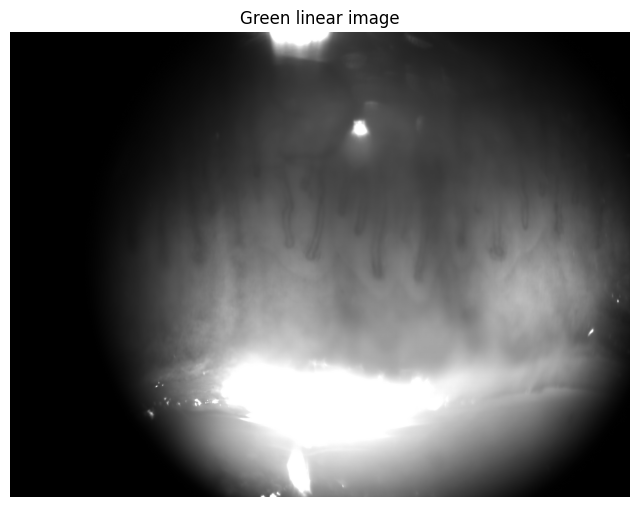

In [ ]:
# Load green linear image

if "metadata" in globals():
    image_id = metadata["image_id"]
    green_npz_path = Path(metadata["outputs"]["green_proxy_npz"])
else:
    image_id = "20260710_164056"
    green_npz_path = Path(
        "../00_Images/3.3x/20260710/processed/20260710_164056/linear/20260710_164056_green_proxy_linear.npz")

print("Loading:", green_npz_path)
data = np.load(green_npz_path)
green = data["green_proxy"].astype(np.float32)

print("Green image shape:", green.shape)
print("Min/max:", np.min(green), np.max(green))


# -----------------------------
# Show image for ROI selection
# -----------------------------

plt.figure(figsize=(8, 8))
plt.imshow(green, cmap="gray", vmin=np.percentile(green, 1), vmax=np.percentile(green, 95.5))
plt.title("Green linear image")
plt.axis("off")
plt.show()

## Select ROIs

In [7]:
# Make display image for ROI selection only

def make_display_uint8(img, p_low=1, p_high=95.5):
    lo, hi = np.percentile(img, [p_low, p_high])
    disp = (img - lo) / max(hi - lo, 1e-8)
    disp = np.clip(disp, 0, 1)
    return (disp * 255).astype(np.uint8)

display_img = make_display_uint8(green)

# Optional resize for easier screen selection
display_scale = 0.32  # use 0.5 if image is too large
if display_scale != 1.0:
    display_for_roi = cv2.resize(
        display_img,
        None,
        fx=display_scale,
        fy=display_scale,
        interpolation=cv2.INTER_AREA
    )
else:
    display_for_roi = display_img.copy()


def show_selected_rois(img, roi_list, title="Selected capillary ROIs"):
    """
    Show selected ROIs as red boxes on the image.
    img: original green linear image
    roi_list: list of dicts with x1, y1, x2, y2
    """

    plt.figure(figsize=(10, 10))

    plt.imshow(
        img,
        cmap="gray",
        vmin=np.percentile(img, 1),
        vmax=np.percentile(img, 95.5)
    )

    ax = plt.gca()

    for roi in roi_list:
        x1 = roi["x1"]
        y1 = roi["y1"]
        x2 = roi["x2"]
        y2 = roi["y2"]

        width = x2 - x1
        height = y2 - y1

        rect = patches.Rectangle(
            (x1, y1),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            y1 - 5,
            f"ROI {roi['roi_id']}",
            color="red",
            fontsize=10,
            weight="bold"
        )

    plt.title(title)
    plt.axis("off")
    plt.show()

# ============================================================
# Interactive multi-ROI selection
# ============================================================
# Instructions:
# - Drag a rectangle around each capillary ROI
# - Press ENTER or SPACE after each ROI
# - Press ESC when done

# rois = cv2.selectROIs(
#     "Select capillary ROIs, ENTER/SPACE to confirm, ESC to finish",
#     display_for_roi,
#     showCrosshair=True,
#     fromCenter=False
# )

# cv2.destroyAllWindows()

# # Convert OpenCV ROIs: x, y, w, h
# roi_list = []

# for i, (x, y, w, h) in enumerate(rois):
#     if w <= 0 or h <= 0:
#         continue

#     x1 = int(round(x / display_scale))
#     y1 = int(round(y / display_scale))
#     x2 = int(round((x + w) / display_scale))
#     y2 = int(round((y + h) / display_scale))

#     roi_list.append({
#         "roi_id": i + 1,
#         "x1": x1,
#         "y1": y1,
#         "x2": x2,
#         "y2": y2
#     })



# print(f"Selected {len(roi_list)} ROIs")
# roi_list

# show_selected_rois(green, roi_list)

#### Draw the region (large) where you want to zoom and press "Enter"
#### From the cropped region, delineate each ROI by drawing and pressing "Enter". It will continue to let you drawe different ROIs till you press the "Esc"


Selected 2 ROIs


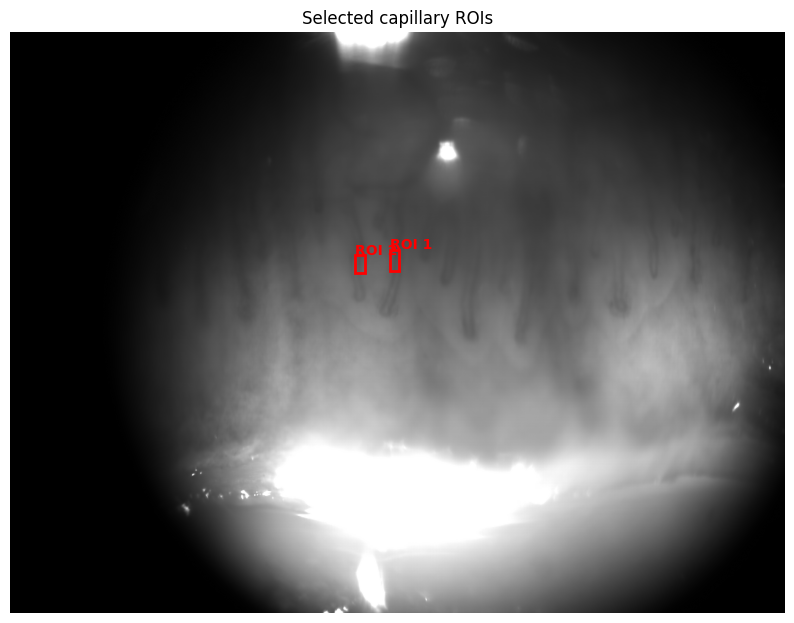

In [8]:
# Stage 1: Select a region to zoom into
zx, zy, zw, zh = cv2.selectROI(
    "Select region to zoom, then press ENTER",
    display_for_roi,
    showCrosshair=True,
    fromCenter=False
)

cv2.destroyAllWindows()

if zw <= 0 or zh <= 0:
    raise ValueError("No zoom region selected.")

# Convert zoom-region coordinates back to original image
zoom_x1 = int(round(zx / display_scale))
zoom_y1 = int(round(zy / display_scale))
zoom_x2 = int(round((zx + zw) / display_scale))
zoom_y2 = int(round((zy + zh) / display_scale))

# Crop from original green image
zoom_crop = green[
    zoom_y1:zoom_y2,
    zoom_x1:zoom_x2
]

# Make a display-friendly version
zoom_display = make_display_uint8(zoom_crop)

# Enlarge it for easier ROI selection
zoom_scale = 2.0

zoom_display_large = cv2.resize(
    zoom_display,
    None,
    fx=zoom_scale,
    fy=zoom_scale,
    interpolation=cv2.INTER_CUBIC
)

# Stage 2: Select multiple ROIs inside enlarged region
rois_zoomed = cv2.selectROIs(
    "Select capillary ROIs, ENTER/SPACE to confirm, ESC to finish",
    zoom_display_large,
    showCrosshair=True,
    fromCenter=False
)

cv2.destroyAllWindows()

# Convert selected ROIs to original-image coordinates
roi_list = []

for i, (x, y, w, h) in enumerate(rois_zoomed):

    if w <= 0 or h <= 0:
        continue

    # Convert from enlarged zoom image to zoom-crop coordinates
    local_x1 = int(round(x / zoom_scale))
    local_y1 = int(round(y / zoom_scale))
    local_x2 = int(round((x + w) / zoom_scale))
    local_y2 = int(round((y + h) / zoom_scale))

    # Convert to original green-image coordinates
    x1 = zoom_x1 + local_x1
    y1 = zoom_y1 + local_y1
    x2 = zoom_x1 + local_x2
    y2 = zoom_y1 + local_y2

    roi_list.append({
        "roi_id": i + 1,
        "x1": x1,
        "y1": y1,
        "x2": x2,
        "y2": y2
    })


print(f"Selected {len(roi_list)} ROIs")

show_selected_rois(green, roi_list)

# Analyze ROIs

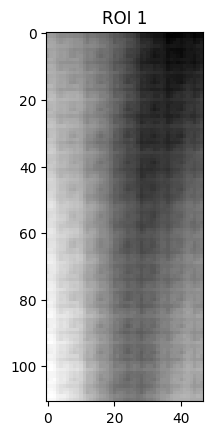

In [9]:
def view_roi(img, roi_list, index):
    roi = roi_list[index]   # index is 0-based

    cropped = img[
        roi["y1"]:roi["y2"],
        roi["x1"]:roi["x2"]
    ]

    plt.imshow(cropped, cmap="gray")
    plt.title(f"ROI {roi['roi_id']}")
    #plt.axis("off")
    plt.show()

    return cropped

cropped_roi = view_roi(green, roi_list, 0)   # first ROI


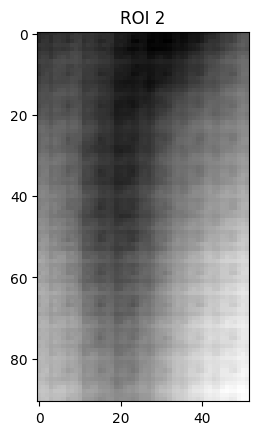

In [10]:
roi = roi_list[1]   # index is 0-based
cropped = green[
        roi["y1"]:roi["y2"],
        roi["x1"]:roi["x2"]
    ]
#cropped = cropped[20:90, :]
plt.imshow(cropped, cmap="gray")
plt.title(f"ROI {roi['roi_id']}")
#plt.axis("off")
plt.show()


## Along Width

In [11]:
def diffusion_inpaint_sparse(img, mask, tol=1e-6, max_iter=2000, use_cg=True):
    """
    Solves the Laplace equation for inpainting. 
    Expects img normalized to [0,1].
    """
    H, W = img.shape
    unknown = mask.copy()
    unknown[0,:] = unknown[-1,:] = unknown[:,0] = unknown[:,-1] = False

    idx = -np.ones((H, W), dtype=np.int32)
    coords = np.argwhere(unknown)
    n = coords.shape[0]
    if n == 0:
        return img.copy()

    idx[coords[:,0], coords[:,1]] = np.arange(n, dtype=np.int32)

    rows, cols, data = [], [], []
    b = np.zeros(n, dtype=np.float32)

    for k, (i, j) in enumerate(coords):
        rows.append(k); cols.append(k); data.append(4.0)

        for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
            ni, nj = i+di, j+dj
            kk = idx[ni, nj]
            if kk >= 0:
                rows.append(k); cols.append(kk); data.append(-1.0)
            else:
                b[k] += img[ni, nj]

    A = sparse.csr_matrix((data, (rows, cols)), shape=(n, n))

    if use_cg:
        x, info = cg(A, b, rtol=tol, maxiter=max_iter)
        if info != 0:
            x = spsolve(A, b)
    else:
        x = spsolve(A, b)

    u = img.copy()
    u[coords[:,0], coords[:,1]] = x.astype(np.float32)
    return np.clip(u, 0.0, 1.0)

In [12]:
def analyze_capillary_profiles(cropped_img, x_min, x_max, y_min, y_max, num_lines, pix_um=0.6, plot_results=True):
    # 1. Image Preparation
    img_crop = cropped_img.astype(np.float32)
    p1, p99 = np.percentile(img_crop, (1, 99))
    img_n = np.clip((img_crop - p1) / (p99 - p1 + 1e-8), 0, 1)

    # 2a. Vessel Masking
    sigmas = np.geomspace(3, 8, 5)
    resp = meijering(img_n, sigmas=sigmas, black_ridges=True) 
    resp = (resp - resp.min()) / (resp.max() - resp.min() + 1e-8)
    BW = resp > threshold_otsu(resp)

    # 2b. Cleanup & Dilation
    BW = closing(BW, disk(2))
    BW = remove_small_objects(BW, min_size=20)
    BW = remove_small_holes(BW, area_threshold=30)
    mask = dilation(BW, disk(2)).astype(bool) 

    # --- 2c. COMPUTE BOTH BACKGROUNDS ---
    
    # Method A: Zero-Bleed (Linear Interpolation)
    h, w = img_crop.shape
    yy, xx = np.mgrid[0:h, 0:w]
    known_mask = ~mask
    coords_known = np.column_stack((yy[known_mask], xx[known_mask]))
    values_known = img_crop[known_mask]
    
    bg_unnorm_lin = interpolate.griddata(coords_known, values_known, (yy, xx), method='linear')
    if np.any(np.isnan(bg_unnorm_lin)):
        bg_unnorm_lin = interpolate.griddata(coords_known, values_known, (yy, xx), method='nearest')
    
    # Method B: Diffusion
    min_val, max_val = img_crop.min(), img_crop.max()
    img_solver_norm = (img_crop - min_val) / (max_val - min_val + 1e-8)
    bg_norm_diff = diffusion_inpaint_sparse(img_solver_norm, mask)
    bg_unnorm_diff = bg_norm_diff * (max_val - min_val) + min_val

    # Optional light smoothing for both
    bg_unnorm_lin = gaussian_filter(bg_unnorm_lin, sigma=3)
    bg_unnorm_diff = gaussian_filter(bg_unnorm_diff, sigma=3)
    
    # Prepare normalized maps for corrected imagery visualizations
    bg_norm_lin_viz = np.clip((bg_unnorm_lin - p1) / (p99 - p1 + 1e-8), 0, 1)
    bg_norm_diff_viz = np.clip((bg_unnorm_diff - p1) / (p99 - p1 + 1e-8), 0, 1)
    img_corr_lin = np.clip(img_n - bg_norm_lin_viz + bg_norm_lin_viz.mean(), 0, 1)
    img_corr_diff = np.clip(img_n - bg_norm_diff_viz + bg_norm_diff_viz.mean(), 0, 1)

    # --- 3. Define Sampling Coordinates ---
    y_coords = np.linspace(y_min, y_max, num_lines)
    profiles_bg_lin, profiles_bg_diff, profiles_cap = [], [], []

    for y in y_coords:
        start_point, end_point = (y, x_min), (y, x_max)
        profiles_bg_lin.append(profile_line(bg_unnorm_lin, start_point, end_point, mode='constant'))
        profiles_bg_diff.append(profile_line(bg_unnorm_diff, start_point, end_point, mode='constant'))
        profiles_cap.append(profile_line(img_crop, start_point, end_point, mode='constant'))

    profiles_bg_lin = np.array(profiles_bg_lin)
    profiles_bg_diff = np.array(profiles_bg_diff)
    profiles_cap = np.array(profiles_cap)

    # --- 4. Statistics and Dataframe ---
    mean_cap, std_cap = np.mean(profiles_cap, axis=0), np.std(profiles_cap, axis=0)
    mean_bg_lin, std_bg_lin = np.mean(profiles_bg_lin, axis=0), np.std(profiles_bg_lin, axis=0)
    mean_bg_diff, std_bg_diff = np.mean(profiles_bg_diff, axis=0), np.std(profiles_bg_diff, axis=0)
    
    N = profiles_cap.shape[1]
    dist_um = np.arange(N) * pix_um

    T_mean = pd.DataFrame({
        'Sample': np.arange(N),
        'Dist_um': dist_um,
        'MeanIntensity_Cap': mean_cap,
        'StdIntensity_Cap': std_cap,
        'MeanIntensity_Bg_Linear': mean_bg_lin,
        'StdIntensity_Bg_Linear': std_bg_lin,
        'MeanIntensity_Bg_Diffusion': mean_bg_diff,
        'StdIntensity_Bg_Diffusion': std_bg_diff
    })
    
    # --- 5. Comparative Plotting ---
    if plot_results:
        print("\n--- Visualizing Background Method Comparison ---")
        
        # FIGURE 1: 2D Spatial Comparison
        fig1, ax1 = plt.subplots(2, 3, figsize=(16, 10))
        
        ax1[0, 0].imshow(img_crop, cmap='gray'); ax1[0, 0].set_title('Original Image')
        for y in y_coords: ax1[0, 0].plot([x_min, x_max], [y, y], 'r-', linewidth=0.5, alpha=0.5)
        ax1[0, 0].axis('off')
        
        ax1[0, 1].imshow(mask, cmap='gray'); ax1[0, 1].set_title('Exclusion Mask')
        ax1[0, 1].axis('off')
        
        # Calculate absolute difference to see where the algorithms disagree
        diff_map = np.abs(bg_unnorm_lin - bg_unnorm_diff)
        im_diff = ax1[0, 2].imshow(diff_map, cmap='inferno')
        ax1[0, 2].set_title('Absolute Difference (Linear vs Diff)')
        fig1.colorbar(im_diff, ax=ax1[0, 2], fraction=0.046, pad=0.04)
        ax1[0, 2].axis('off')

        ax1[1, 0].imshow(bg_unnorm_lin, cmap='gray'); ax1[1, 0].set_title('Zero-Bleed BG (Linear)')
        ax1[1, 0].axis('off')
        
        ax1[1, 1].imshow(bg_unnorm_diff, cmap='gray'); ax1[1, 1].set_title('Inpainted BG (Diffusion)')
        ax1[1, 1].axis('off')
        
        ax1[1, 2].imshow(img_corr_diff, cmap='gray'); ax1[1, 2].set_title('Corrected Image (via Diffusion)')
        ax1[1, 2].axis('off')
        
        plt.tight_layout()
        plt.show()

        # FIGURE 2: Profile Line Comparison
        fig2, ax2 = plt.subplots(figsize=(10, 6))
        ax2.grid(True, alpha=0.3)
        
        # Capillary Profile
        ax2.plot(dist_um, mean_cap, 'k-', linewidth=2, label='Capillary Profile')
        ax2.fill_between(dist_um, mean_cap - std_cap, mean_cap + std_cap, color='black', alpha=0.1)
        
        # Linear BG
        ax2.plot(dist_um, mean_bg_lin, 'g--', linewidth=2, label='Inpainted BG (Linear)')
        ax2.fill_between(dist_um, mean_bg_lin - std_bg_lin, mean_bg_lin + std_bg_lin, color='green', alpha=0.1)
        
        # Diffusion BG
        ax2.plot(dist_um, mean_bg_diff, 'b--', linewidth=2, label='Inpainted BG (Diffusion)')
        ax2.fill_between(dist_um, mean_bg_diff - std_bg_diff, mean_bg_diff + std_bg_diff, color='blue', alpha=0.1)
        
        ax2.set_xlabel('Distance (µm)', fontsize=12)
        ax2.set_ylabel('16-bit Intensity', fontsize=12)
        ax2.set_title('Cross-Sectional Profile Comparison', fontsize=14)
        ax2.legend(loc='lower right', fontsize=11)
        
        plt.tight_layout()
        plt.show()
        
    return T_mean

### Run

In [13]:
crop_display = make_display_uint8(cropped_roi)
selection_scale = 4.0

crop_display_large = cv2.resize(
    crop_display,
    None,
    fx=selection_scale,
    fy=selection_scale,
    interpolation=cv2.INTER_CUBIC
)

# Select the region containing the vessel/profile area
x, y, w, h = cv2.selectROI(
    "Select profile region, then press ENTER",
    crop_display_large,
    showCrosshair=True,
    fromCenter=False
)

cv2.destroyAllWindows()

if w <= 0 or h <= 0:
    raise ValueError("No profile region was selected.")

# Convert coordinates back to cropped_roi coordinates
x_min = int(round(x / selection_scale))
y_min = int(round(y / selection_scale))

x_max = int(round((x + w) / selection_scale)) - 1
y_max = int(round((y + h) / selection_scale)) - 1

# Keep coordinates inside the image
H, W = cropped_roi.shape[:2]

x_min = np.clip(x_min, 0, W - 1)
x_max = np.clip(x_max, 0, W - 1)
y_min = np.clip(y_min, 0, H - 1)
y_max = np.clip(y_max, 0, H - 1)

print("x_min:", x_min)
print("x_max:", x_max)
print("y_min:", y_min)
print("y_max:", y_max)

x_min: 25
x_max: 34
y_min: 17
y_max: 69



--- Visualizing Background Method Comparison ---


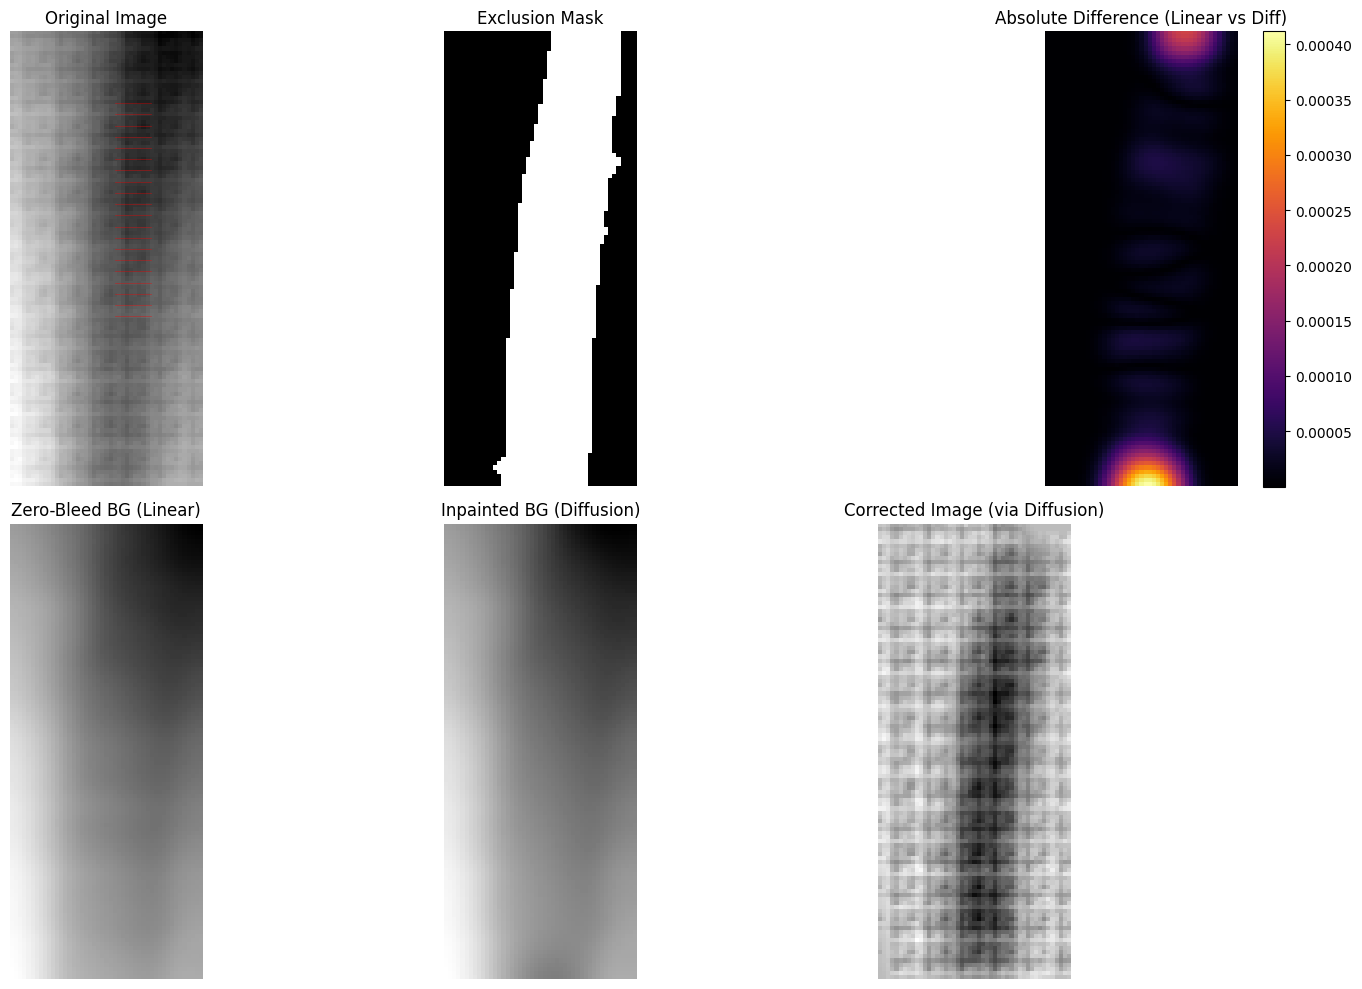

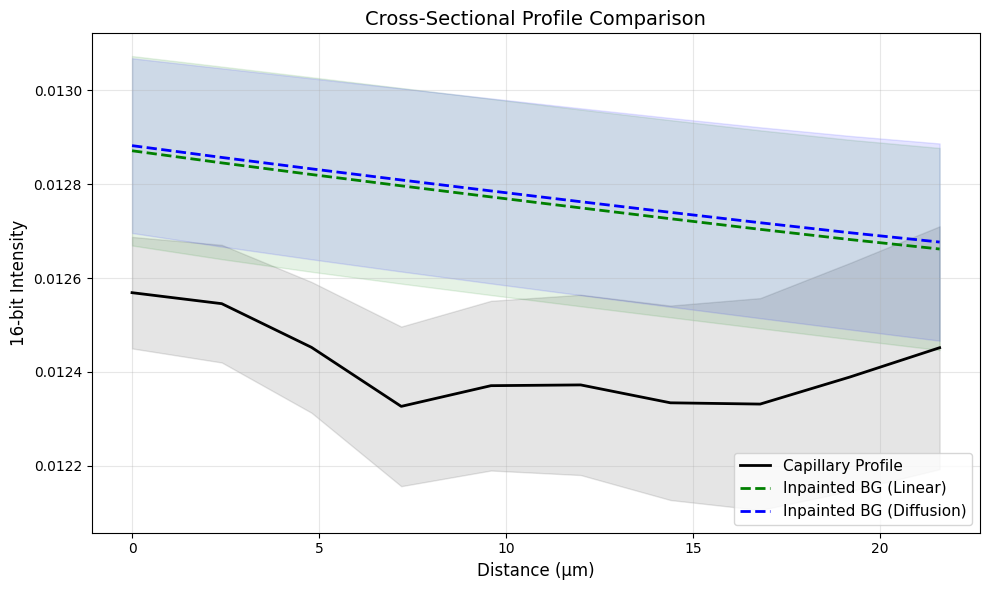

In [14]:
mean_profiles_df = analyze_capillary_profiles(
    cropped_roi,
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    num_lines=20,
    pix_um=2.4,
    plot_results=True
)

In [15]:
region_df = mean_profiles_df.copy()

region_df["OD"] = -np.log10(
    (region_df["MeanIntensity_Cap"] + 1e-8) /
    (region_df["MeanIntensity_Bg_Diffusion"] + 1e-8)
)

OD_mean = region_df["OD"].mean()
OD_std = region_df["OD"].std()

print(
    f"Mean OD over the selected region: "
    f"{OD_mean:.10f} ± {OD_std:.10f}"
)

Mean OD over the selected region: 0.0124833155 ± 0.0025317830


In [16]:
def od_to_hgb(od):
    return (od + 0.0098) / 0.0022

hb_mean = od_to_hgb(OD_mean)
hb_std = OD_std / 0.01422

print(f"Hemoglobin level: {hb_mean:.2f} ± {hb_std:.2f} g/dL")

Hemoglobin level: 10.13 ± 0.18 g/dL


# Across all ROIs

In [ ]:
def analyze_all_rois(
    green,
    roi_list,
    pix_um=2.4,
    num_lines=20,
    selection_scale=4.0,
    plot_results=True
):
    roi_summaries = []
    all_sample_results = []

    for roi in roi_list:
        roi_id = roi["roi_id"]

        # Crop the current ROI from the original green image
        cropped_roi = green[
            roi["y1"]:roi["y2"],
            roi["x1"]:roi["x2"]
        ]

        H, W = cropped_roi.shape[:2]

        try:

            # Interactive profile-region selection for this ROI
            crop_display = make_display_uint8(cropped_roi)

            crop_display_large = cv2.resize(
                crop_display,
                None,
                fx=selection_scale,
                fy=selection_scale,
                interpolation=cv2.INTER_CUBIC
            )

            x, y, selected_w, selected_h = cv2.selectROI(
                f"ROI {roi_id}: Select profile region, then press ENTER",
                crop_display_large,
                showCrosshair=True,
                fromCenter=False
            )

            cv2.destroyAllWindows()

            if selected_w <= 0 or selected_h <= 0:
                raise ValueError("Profile-region selection cancelled.")

            # Convert selection coordinates back to cropped_roi scale
            x_min = int(round(x / selection_scale))
            y_min = int(round(y / selection_scale))

            x_max = int(
                round((x + selected_w) / selection_scale)
            ) - 1

            y_max = int(
                round((y + selected_h) / selection_scale)
            ) - 1

            # Keep coordinates inside cropped_roi
            x_min = int(np.clip(x_min, 0, W - 1))
            x_max = int(np.clip(x_max, 0, W - 1))
            y_min = int(np.clip(y_min, 0, H - 1))
            y_max = int(np.clip(y_max, 0, H - 1))

            print(
                f"\nROI {roi_id}: "
                f"x=[{x_min}, {x_max}], "
                f"y=[{y_min}, {y_max}]"
            )

            # Analyze the manually selected region
            mean_profiles_df = analyze_capillary_profiles(
                cropped_roi,
                x_min=x_min,
                x_max=x_max,
                y_min=y_min,
                y_max=y_max,
                num_lines=num_lines,
                pix_um=pix_um,
                plot_results=plot_results
            )

            # Calculate OD at each profile position
            mean_profiles_df["OD"] = -np.log10(
                (
                    mean_profiles_df["MeanIntensity_Cap"] + 1e-8
                ) / (
                    mean_profiles_df[
                        "MeanIntensity_Bg_Diffusion"
                    ] + 1e-8
                )
            )

            # Convert each OD value to Hb
            mean_profiles_df["Hb_g_dL"] = od_to_hgb(
                mean_profiles_df["OD"]
            )

            mean_profiles_df["roi_id"] = roi_id
            mean_profiles_df["x_min"] = x_min
            mean_profiles_df["x_max"] = x_max
            mean_profiles_df["y_min"] = y_min
            mean_profiles_df["y_max"] = y_max

            od_mean = mean_profiles_df["OD"].mean()
            od_std = mean_profiles_df["OD"].std(ddof=0)

            hb_mean = od_to_hgb(od_mean)
            hb_std = od_std / 0.01422

            roi_summaries.append({
                "roi_id": roi_id,
                "x_min": x_min,
                "x_max": x_max,
                "y_min": y_min,
                "y_max": y_max,
                "OD_mean": od_mean,
                "OD_std": od_std,
                "Hb_mean_g_dL": hb_mean,
                "Hb_std_g_dL": hb_std,
                "n_samples": len(mean_profiles_df),
                "status": "Success"
            })

            all_sample_results.append(mean_profiles_df)

        except Exception as exc:
            cv2.destroyAllWindows()

            roi_summaries.append({
                "roi_id": roi_id,
                "x_min": np.nan,
                "x_max": np.nan,
                "y_min": np.nan,
                "y_max": np.nan,
                "OD_mean": np.nan,
                "OD_std": np.nan,
                "Hb_mean_g_dL": np.nan,
                "Hb_std_g_dL": np.nan,
                "n_samples": 0,
                "status": str(exc)
            })

    # Combine results
    summary_df = pd.DataFrame(roi_summaries)

    if all_sample_results:
        combined_results_df = pd.concat(
            all_sample_results,
            ignore_index=True
        )
    else:
        combined_results_df = pd.DataFrame()

    valid_rois = summary_df[
        summary_df["status"] == "Success"
    ].copy()

    # Equal weighting across successful ROIs
    if len(valid_rois) > 0:
        overall_od_mean = valid_rois["OD_mean"].mean()
        overall_od_std = valid_rois["OD_mean"].std(ddof=0)

        overall_hgb_mean = od_to_hgb(overall_od_mean)
        overall_hgb_std = overall_od_std / 0.01422
    else:
        overall_od_mean = np.nan
        overall_od_std = np.nan
        overall_hgb_mean = np.nan
        overall_hgb_std = np.nan

    overall_summary_df = pd.DataFrame([{
        "n_successful_rois": len(valid_rois),
        "OD_mean_across_ROIs": overall_od_mean,
        "OD_std_across_ROIs": overall_od_std,
        "Hb_mean_g_dL": overall_hgb_mean,
        "Hb_std_g_dL": overall_hgb_std
    }])

    return summary_df, combined_results_df, overall_summary_df

### Estimated Hgb

In [17]:
summary_df, combined_results_df, overall_summary_df = analyze_all_rois(
    green,
    roi_list,
    pix_um=2.4,
    num_lines=20,
    selection_scale=4.0,
    plot_results=False
)

display(summary_df)

hb_mean = overall_summary_df.loc[0, "Hb_mean_g_dL"]
hb_std = overall_summary_df.loc[0, "Hb_std_g_dL"]

print(
    f"Mean hemoglobin level across ROIs: "
    f"{hb_mean:.2f} ± {hb_std:.2f} g/dL"
)


ROI 1: x=[24, 31], y=[9, 39]

ROI 2: x=[13, 23], y=[10, 39]

ROI 3: x=[32, 39], y=[10, 47]


,roi_id,x_min,x_max,y_min,y_max,OD_mean,OD_std,Hb_mean_g_dL,Hb_std_g_dL,n_samples,status
0,1,24,31,9,39,0.016576,0.002553,11.988977,0.179515,8,Success
1,2,13,23,10,39,0.015217,0.002394,11.371235,0.168339,11,Success
2,3,32,39,10,47,0.012030,0.001955,9.922865,0.137461,8,Success


Mean hemoglobin level across ROIs: 11.09 ± 0.13 g/dL


In [18]:
import tkinter as tk
from tkinter import ttk, messagebox


def classify_hgb_from_chart(hgb, age, gender, pregnant):
    if age < 1 / 12:
        group = "Newborn"
        normal_low, normal_high = 14.0, 24.0

    elif age < 1:
        group = "Infant"
        normal_low, normal_high = 9.5, 14.0

    elif age <= 10:
        group = "Child"
        normal_low, normal_high = 11.0, 16.0

    elif age > 60:
        group = "Elderly"
        normal_low, normal_high = 11.0, 16.0

    elif gender == "Female" and pregnant == "Yes":
        group = "Pregnant woman"
        normal_low, normal_high = 11.0, 14.0

    elif gender == "Male":
        group = "Adult male"
        normal_low, normal_high = 13.8, 17.2

    else:
        group = "Adult female"
        normal_low, normal_high = 12.1, 15.1

    if hgb < normal_low:
        status = "Low"
    elif hgb > normal_high:
        status = "High"
    else:
        status = "Normal"

    return group, normal_low, normal_high, status


def show_hgb_status_popup(hgb_value):
    root = tk.Tk()
    root.title("Hemoglobin Status")
    root.geometry("440x360")
    root.resizable(False, False)

    age_var = tk.StringVar()
    gender_var = tk.StringVar(value="Female")
    pregnancy_var = tk.StringVar(value="No")
    result_var = tk.StringVar()

    ttk.Label(
        root,
        text=f"Estimated Hb: {hgb_value:.2f} g/dL",
        font=("Arial", 15, "bold")
    ).pack(pady=(20, 15))

    form = ttk.Frame(root)
    form.pack(padx=25, fill="x")

    ttk.Label(form, text="Age in years:").grid(row=0, column=0, sticky="w", pady=8)
    ttk.Entry(form, textvariable=age_var, width=22).grid(row=0, column=1, pady=8)

    ttk.Label(form, text="Gender:").grid(row=1, column=0, sticky="w", pady=8)
    ttk.Combobox(
        form,
        textvariable=gender_var,
        values=["Female", "Male"],
        state="readonly",
        width=19
    ).grid(row=1, column=1, pady=8)

    ttk.Label(form, text="Pregnant:").grid(row=2, column=0, sticky="w", pady=8)
    ttk.Combobox(
        form,
        textvariable=pregnancy_var,
        values=["No", "Yes"],
        state="readonly",
        width=19
    ).grid(row=2, column=1, pady=8)

    def submit():
        try:
            age = float(age_var.get())

            if age < 0:
                raise ValueError

            gender = gender_var.get()
            pregnant = pregnancy_var.get()

            if gender == "Male" and pregnant == "Yes":
                messagebox.showerror(
                    "Invalid information",
                    "Pregnancy status cannot be Yes when gender is Male."
                )
                return

            group, low, high, status = classify_hgb_from_chart(
                hgb=hgb_value,
                age=age,
                gender=gender,
                pregnant=pregnant
            )

            result_var.set(
                f"Group: {group}\n"
                f"Reference range: {low:.1f}–{high:.1f} g/dL\n"
                f"Your Hb status: {status}"
            )

        except ValueError:
            messagebox.showerror(
                "Invalid age",
                "Enter a valid age. Use 0.5 for six months."
            )

    ttk.Button(root, text="Calculate Status", command=submit).pack(pady=18)

    ttk.Label(
        root,
        textvariable=result_var,
        font=("Arial", 12),
        justify="center"
    ).pack(pady=5)

    # Bring the popup to the front
    root.update_idletasks()
    root.lift()
    root.attributes("-topmost", True)
    root.after(500, lambda: root.attributes("-topmost", False))

    root.mainloop()


# This call must remain outside the function
show_hgb_status_popup(float(hb_mean))

# End demo analysis here

In [ ]:
# mean_profiles_df = analyze_capillary_profiles(
#     cropped,
#     x_min=15,
#     x_max=35,
#     y_min=25,
#     y_max=45,
#     num_lines=30,
#     pix_um=2.4,
#     plot_results=True
# )

# #mean_profiles_df

In [ ]:
# od_x_min = 17
# od_x_max = 30

# region_df = mean_profiles_df[
#     (mean_profiles_df["Dist_um"] >= od_x_min) &
#     (mean_profiles_df["Dist_um"] <= od_x_max)
# ].copy()

# region_df["OD"] = -np.log10(
#     (region_df["MeanIntensity_Cap"] + 1e-8) /
#     (region_df["MeanIntensity_Bg_Diffusion"] + 1e-8)
# )

# OD_mean = region_df["OD"].mean()
# OD_std = region_df["OD"].std()

# print(
#     f"Mean OD from {od_x_min} to {od_x_max} µm: "
#     f"{OD_mean:.10f} ± {OD_std:.10f}"
# )

# plt.figure(figsize=(10, 6))

# plt.plot(
#     mean_profiles_df["Dist_um"],
#     mean_profiles_df["MeanIntensity_Cap"],
#     "k-",
#     linewidth=2,
#     label="Capillary Profile"
# )

# plt.plot(
#     mean_profiles_df["Dist_um"],
#     mean_profiles_df["MeanIntensity_Bg_Diffusion"],
#     "b--",
#     linewidth=2,
#     label="Inpainted BG (Diffusion)"
# )

# plt.axvspan(
#     od_x_min,
#     od_x_max,
#     alpha=0.2,
#     label="OD measurement region"
# )

# plt.xlabel("Distance (µm)")
# plt.ylabel("Intensity")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

## Along Centerline

In [ ]:

def diffusion_inpaint_sparse(
    img,
    mask,
    tol=1e-6,
    max_iter=2000,
    use_cg=True
):
    """
    Solve the Laplace equation for diffusion-based inpainting.

    img must be normalized to [0, 1].
    mask=True indicates pixels that should be reconstructed.
    """

    H, W = img.shape

    unknown = mask.copy().astype(bool)

    # Boundary pixels must remain known
    unknown[0, :] = False
    unknown[-1, :] = False
    unknown[:, 0] = False
    unknown[:, -1] = False

    idx = -np.ones((H, W), dtype=np.int32)

    coords = np.argwhere(unknown)
    n = coords.shape[0]

    if n == 0:
        return img.copy()

    idx[coords[:, 0], coords[:, 1]] = np.arange(
        n,
        dtype=np.int32
    )

    rows = []
    cols = []
    data = []

    b = np.zeros(n, dtype=np.float32)

    for k, (i, j) in enumerate(coords):

        rows.append(k)
        cols.append(k)
        data.append(4.0)

        for di, dj in [
            (-1, 0),
            (1, 0),
            (0, -1),
            (0, 1)
        ]:

            ni = i + di
            nj = j + dj

            kk = idx[ni, nj]

            if kk >= 0:
                rows.append(k)
                cols.append(kk)
                data.append(-1.0)

            else:
                b[k] += img[ni, nj]

    A = sparse.csr_matrix(
        (data, (rows, cols)),
        shape=(n, n)
    )

    if use_cg:

        x, info = cg(
            A,
            b,
            rtol=tol,
            maxiter=max_iter
        )

        if info != 0:
            x = spsolve(A, b)

    else:
        x = spsolve(A, b)

    output = img.copy()

    output[
        coords[:, 0],
        coords[:, 1]
    ] = x.astype(np.float32)

    return np.clip(output, 0.0, 1.0)


def segment_for_skeleton(img_input):
    """
    Vessel segmentation parameters adjusted for a small crop
    of approximately 50 x 70 pixels.
    """

    img_f = img_input.astype(np.float32)

    # Changed from disk(50) to disk(8)
    footprint = disk(8)

    hat = black_tophat(
        img_f,
        footprint
    )

    threshold = threshold_otsu(hat)

    BW = hat > threshold

    # Changed from disk(20) to disk(3)
    BW = binary_closing(
        BW,
        disk(3)
    )

    # Changed from min_size=3000 to min_size=50
    BW = remove_small_objects(
        BW,
        min_size=50
    )

    # Keep only the largest connected component
    labels = label(BW)

    if labels.max() > 0:

        counts = np.bincount(
            labels.ravel()
        )

        largest_label = (
            np.argmax(counts[1:]) + 1
        )

        BW = labels == largest_label

    return BW


def analyze_robust_v5(
    img_input,
    y_min,
    y_max,
    x_min,
    x_max,
    spine_thickness=3,
    pix_um=2.4
):
    """
    Extract capillary and reconstructed-background intensities
    along the detected vessel centerline.
    """

    img_input = img_input.astype(np.float32)

    H, W = img_input.shape

    # Keep coordinates inside the image
    x_min = max(0, int(x_min))
    x_max = min(W - 1, int(x_max))

    y_min = max(0, int(y_min))
    y_max = min(H - 1, int(y_max))

    # ========================================================
    # 1. Masking and skeletonization
    # ========================================================

    BW = segment_for_skeleton(
        img_input
    )

    skeleton = skeletonize(BW)

    # ========================================================
    # 2. Keep the main skeleton component
    # ========================================================

    skel_labels = label(skeleton)

    props = regionprops(
        skel_labels
    )

    if len(props) > 0:

        main_region = max(
            props,
            key=lambda p: np.sqrt(
                (p.bbox[2] - p.bbox[0]) ** 2
                +
                (p.bbox[3] - p.bbox[1]) ** 2
            )
        )

        trunk_skeleton = (
            skel_labels == main_region.label
        )

    else:
        trunk_skeleton = skeleton

    # ========================================================
    # 3. Restrict skeleton to the selected coordinate range
    # ========================================================

    # clean_mask = np.zeros_like(
    #     skeleton,
    #     dtype=bool
    # )

    # trunk_coords = np.argwhere(
    #     trunk_skeleton
    # )

    # for r, c in trunk_coords:

    #     if (
    #         y_min <= r <= y_max
    #         and
    #         x_min <= c <= x_max
    #     ):
    #         clean_mask[r, c] = True

    # # Changed default thickness from 20 to 5
    # thick_spine = binary_dilation(
    #     clean_mask,
    #     disk(max(1, spine_thickness // 2))
    # )

    # 3. CLEAN SINGLE-PATH CENTERLINE
    is_horizontal = (x_max - x_min) > (y_max - y_min)

    clean_mask = np.zeros_like(trunk_skeleton, dtype=bool)

    if not is_horizontal:
        # Vertical vessel: choose one central x-position per row
        detected_y = []
        detected_x = []

        for r in range(y_min, y_max + 1):
            cols = np.where(
                trunk_skeleton[r, x_min:x_max + 1]
            )[0] + x_min

            if len(cols) > 0:
                detected_y.append(r)
                detected_x.append(np.median(cols))

        if len(detected_y) > 1:
            detected_y = np.asarray(detected_y)
            detected_x = np.asarray(detected_x)

            # Fill gaps and smooth lateral movement
            full_y = np.arange(detected_y.min(), detected_y.max() + 1)
            full_x = np.interp(full_y, detected_y, detected_x)
            full_x = median_filter(full_x, size=5, mode="nearest")
            full_x = np.rint(full_x).astype(int)

            clean_mask[full_y, full_x] = True

    else:
        # Horizontal vessel: choose one central y-position per column
        detected_x = []
        detected_y = []

        for c in range(x_min, x_max + 1):
            rows = np.where(
                trunk_skeleton[y_min:y_max + 1, c]
            )[0] + y_min

            if len(rows) > 0:
                detected_x.append(c)
                detected_y.append(np.median(rows))

        if len(detected_x) > 1:
            detected_x = np.asarray(detected_x)
            detected_y = np.asarray(detected_y)

            # Fill gaps and smooth vertical movement
            full_x = np.arange(detected_x.min(), detected_x.max() + 1)
            full_y = np.interp(full_x, detected_x, detected_y)
            full_y = median_filter(full_y, size=5, mode="nearest")
            full_y = np.rint(full_y).astype(int)

            clean_mask[full_y, full_x] = True

    thick_spine = dilation(
        clean_mask,
        disk(max(1, spine_thickness // 2))
    )

    # ========================================================
    # 4. Diffusion-based background reconstruction
    # ========================================================

    raw_min = float(
        img_input.min()
    )

    raw_max = float(
        img_input.max()
    )

    img_solver_norm = (
        img_input - raw_min
    ) / (
        raw_max - raw_min + 1e-8
    )

    # Changed from disk(110) to disk(8)
    bg_mask = dilation(
        BW,
        disk(8)
    ).astype(bool)

    bg_norm = diffusion_inpaint_sparse(
        img_solver_norm,
        bg_mask
    )

    bg_raw = (
        bg_norm * (raw_max - raw_min)
        + raw_min
    )

    bg_raw = gaussian_filter(
        bg_raw,
        sigma=5
    )

    # ========================================================
    # 5. Extract intensity along vessel
    # ========================================================

    img_raw_smooth = gaussian_filter(
        img_input,
        sigma=1.0
    )

    is_horizontal = (
        x_max - x_min
    ) > (
        y_max - y_min
    )

    y_idx, x_idx = np.where(
        thick_spine
    )

    if is_horizontal:
        unique_coords = np.unique(
            x_idx
        )
    else:
        unique_coords = np.unique(
            y_idx
        )

    unique_coords.sort()

    I_cap_list = []
    I_bg_list = []

    final_y = []
    final_x = []

    for coord in unique_coords:

        if is_horizontal:

            rows = np.where(
                thick_spine[:, coord]
            )[0]

            valid_rows = rows[
                (rows >= y_min)
                &
                (rows <= y_max)
            ]

            if len(valid_rows) > 0:

                I_cap_list.append(
                    np.mean(
                        img_raw_smooth[
                            valid_rows,
                            coord
                        ]
                    )
                )

                I_bg_list.append(
                    np.mean(
                        bg_raw[
                            valid_rows,
                            coord
                        ]
                    )
                )

                final_x.append(
                    float(coord)
                )

                final_y.append(
                    float(np.mean(valid_rows))
                )

        else:

            cols = np.where(
                thick_spine[coord, :]
            )[0]

            valid_cols = cols[
                (cols >= x_min)
                &
                (cols <= x_max)
            ]

            if len(valid_cols) > 0:

                I_cap_list.append(
                    np.mean(
                        img_raw_smooth[
                            coord,
                            valid_cols
                        ]
                    )
                )

                I_bg_list.append(
                    np.mean(
                        bg_raw[
                            coord,
                            valid_cols
                        ]
                    )
                )

                final_y.append(
                    float(coord)
                )

                final_x.append(
                    float(np.mean(valid_cols))
                )

    # Prevent the previous x/y length error
    if len(final_x) == 0:

        fig, ax = plt.subplots(
            1,
            3,
            figsize=(16, 5)
        )

        ax[0].imshow(
            img_input,
            cmap="gray"
        )

        rect = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            edgecolor="yellow",
            facecolor="none",
            linestyle="--",
            linewidth=2
        )

        ax[0].add_patch(rect)
        ax[0].set_title("ROI")

        ax[1].imshow(
            BW,
            cmap="gray"
        )

        ax[1].set_title(
            "Binary Mask"
        )

        ax[2].imshow(
            skeleton,
            cmap="gray"
        )

        ax[2].set_title(
            "Skeleton"
        )

        for a in ax:
            a.axis("off")

        plt.tight_layout()
        plt.show()

        raise ValueError(
            "No skeleton pixels were detected inside the selected "
            "x/y range. Check the ROI coordinates or segmentation mask."
        )

    # ========================================================
    # 6. Distance along vessel
    # ========================================================

    coords_array = np.column_stack(
        (final_y, final_x)
    )

    diffs = np.diff(
        coords_array,
        axis=0
    )

    step_sizes = np.sqrt(
        (diffs ** 2).sum(axis=1)
    )

    cumulative_dist = np.concatenate(
        ([0.0], np.cumsum(step_sizes))
    ) * pix_um

    I_cap_array = np.asarray(
        I_cap_list,
        dtype=np.float32
    )

    I_bg_array = np.asarray(
        I_bg_list,
        dtype=np.float32
    )

   # ========================================================
# 7. Plotting: 2 × 2 layout
# ========================================================

    fig, ax = plt.subplots(
        2,
        2,
        figsize=(14, 12)
    )

    # --------------------------------------------------------
    # Image 1: ROI and detected centerline
    # --------------------------------------------------------

    ax[0, 0].imshow(
        img_input,
        cmap="gray"
    )

    ax[0, 0].imshow(
        np.ma.masked_where(~thick_spine, thick_spine),
        cmap="Reds",
        alpha=0.45
    )

    rect = plt.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        edgecolor="yellow",
        facecolor="none",
        linestyle="--",
        linewidth=2
    )

    ax[0, 0].add_patch(rect)
    ax[0, 0].set_title("1. ROI & Detection")
    ax[0, 0].axis("off")


    # --------------------------------------------------------
    # Image 2: Binary mask
    # --------------------------------------------------------

    ax[0, 1].imshow(
        BW,
        cmap="gray"
    )

    ax[0, 1].set_title("2. Binary Mask")
    ax[0, 1].axis("off")


    # --------------------------------------------------------
    # Image 3: Binary mask overlaid on original image
    # --------------------------------------------------------

    mask_overlay = np.ma.masked_where(
        ~BW.astype(bool),
        BW.astype(bool)
    )

    ax[1, 0].imshow(
        img_input,
        cmap="gray"
    )

    ax[1, 0].imshow(
        mask_overlay,
        cmap="Reds",
        alpha=0.40
    )

    ax[1, 0].set_title("3. Binary Mask Overlay")
    ax[1, 0].axis("off")


    # --------------------------------------------------------
    # Image 4: Intensity profiles
    # --------------------------------------------------------

    ax[1, 1].plot(
        cumulative_dist,
        I_bg_array,
        "b-",
        label=r"Background ($I_0$)",
        linewidth=2
    )

    ax[1, 1].plot(
        cumulative_dist,
        I_cap_array,
        "k-",
        label=r"Capillary ($I$)",
        linewidth=2
    )

    ax[1, 1].set_xlabel(
        r"Distance along vessel path ($\mu m$)"
    )

    ax[1, 1].set_ylabel(
        "Pixel Intensity (A.U.)"
    )

    ax[1, 1].set_title(
        "4. Intensity Profiles"
    )

    ax[1, 1].legend(
        loc="best"
    )

    ax[1, 1].grid(
        True,
        linestyle=":",
        alpha=0.6
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # 8. DataFrame
    # ========================================================

    results_df = pd.DataFrame({
        "dist_um": cumulative_dist,
        "X": final_x,
        "Y": final_y,
        "I_cap": I_cap_array,
        "I_bg": I_bg_array
    })

    return results_df

### Run

In [ ]:
results_df = analyze_robust_v5(
    cropped,
    x_min=15,
    x_max=35,
    y_min=25,
    y_max=45,
    spine_thickness=5,
    pix_um=2.4
)

# results_df

In [ ]:
results_df["OD"] = -np.log10(
    (results_df["I_cap"] + 1e-8) / 
    (results_df["I_bg"] + 1e-8)
)

OD_mean = results_df["OD"].mean()
OD_std = results_df["OD"].std()

print(f"Mean OD along vessel: {OD_mean:.10f} ± {OD_std:.10f}")

# Summary

In [ ]:
def analyze_all_rois(
    green,
    roi_list,
    pix_um=2.4,
    spine_thickness=5
):
    roi_summaries = []
    all_sample_results = []

    for roi in roi_list:
        roi_id = roi["roi_id"]

        cropped = green[
            roi["y1"]:roi["y2"],
            roi["x1"]:roi["x2"]
        ]

        h, w = cropped.shape

        try:
            # Assumes the ROI tightly surrounds one capillary
            results_df = analyze_robust_v5(
                cropped,
                x_min=1,
                x_max=max(1, w - 2),
                y_min=1,
                y_max=max(1, h - 2),
                spine_thickness=spine_thickness,
                pix_um=pix_um
            )

            results_df["OD"] = -np.log10(
                (results_df["I_cap"] + 1e-8) /
                (results_df["I_bg"] + 1e-8)
            )

            results_df["roi_id"] = roi_id

            roi_summaries.append({
                "roi_id": roi_id,
                "OD_mean": results_df["OD"].mean(),
                "OD_std": results_df["OD"].std(),
                "n_samples": len(results_df),
                "status": "Success"
            })

            all_sample_results.append(results_df)

        except Exception as exc:
            roi_summaries.append({
                "roi_id": roi_id,
                "OD_mean": np.nan,
                "OD_std": np.nan,
                "n_samples": 0,
                "status": str(exc)
            })

    summary_df = pd.DataFrame(roi_summaries)

    if all_sample_results:
        combined_results_df = pd.concat(
            all_sample_results,
            ignore_index=True
        )
    else:
        combined_results_df = pd.DataFrame()

    return summary_df, combined_results_df

In [ ]:
summary_df, combined_results_df = analyze_all_rois(
    green,
    roi_list,
    pix_um=2.4,
    spine_thickness=5
)

summary_df